In [1]:
import sys
import os

sys.path.insert(0, os.path.abspath("."))
sys.path.append(os.path.abspath("../../../"))

In [2]:
from desc import set_device
set_device("gpu")

/pscratch/sd/r/rgaur/DESC/desc/__init__.py:94: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  from pynvml import (


As mentioned in [DESC Documentation on performance tips](https://desc-docs.readthedocs.io/en/latest/performance_tips.html), one can use compilation cache directory to reduce the compilation overhead time. Uncomment the next code block to take advantage of the cache.

Note: One needs to create jax-caches folder manually.

In [3]:
import jax

jax.config.update("jax_compilation_cache_dir", "../jax-caches")
jax.config.update("jax_persistent_cache_min_entry_size_bytes", -1)
jax.config.update("jax_persistent_cache_min_compile_time_secs", 0)

In [4]:
import numpy as np
from desc.coils import (
    CoilSet,
    FourierPlanarCoil,
    MixedCoilSet,
    initialize_modular_coils,
    initialize_saddle_coils,
)
import desc.examples
from desc.equilibrium import Equilibrium
from desc.plotting import plot_2d, plot_3d, plot_coils, plot_comparison
from desc.grid import LinearGrid
from desc.objectives import (
    ObjectiveFunction,
    CoilCurvature,
    CoilLength,
    CoilTorsion,
    CoilSetLinkingNumber,
    CoilSetMinDistance,
    PlasmaCoilSetMinDistance,
    SurfaceQuadraticFlux,
    SurfaceMatch,
    ToroidalFlux,
    Volume,
    FixSumCoilCurrent,
    FixParameters,
    get_fixed_boundary_constraints,
    ForceBalance,
    Elongation,
    SLAMElongation,
    SLAMCenter,
    SLAMStraightSectionCenter
)
from desc.geometry import FourierRZToroidalSurface
from desc.coils import CoilSet
from desc.optimize import Optimizer
from desc.integrals import compute_B_plasma
from scipy.optimize import fsolve, minimize
from desc.magnetic_fields import field_line_integrate
from desc.plotting import *
from matplotlib import pyplot as plt
import time
import plotly.express as px
import plotly.io as pio
from desc.io import load
# This ensures Plotly output works in multiple places:
# plotly_mimetype: VS Code notebook UI
# notebook: "Jupyter: Export to HTML" command in VS Code
# See https://plotly.com/python/renderers/#multiple-renderers
pio.renderers.default = "plotly_mimetype+notebook"

## Coil Optimization Metrics

Two main figures of merit regarding the quality of the coil optimization in recreating the equilibrium are the average normalized magnetic field and Poincare plot from the coils. The average normalized magnetic field is a measure of how well the coils' field (plus the plasma field if it is finite beta) recreates last closed flux surface of the target equilibrium and is given as 
$$
\frac{\left<|\mathbf{B}_{\text{total}}\cdot \mathbf{\hat{n}}|\right>}{\left<|\mathbf{B}_{\text{total}}|\right>}
$$
where $\mathbf{\hat{n}}$ is the normal vector to the equilibrium's last closed flux surface and $\mathbf{B}_{\text{total}} = \mathbf{B}_{\text{coils}} + \mathbf{B}_{\text{plasma currents}}$. Field traces are also significant for vacuum equilibria because they visually show the quality of the coil field in recreating the equilibrium vacuum flux surfaces.

These two metrics are calculated in functions below.

In [5]:
def compute_average_normalized_field(
    field, eq, vacuum=False, chunk_size=None, B_plasma_chunk_size=None
):
    if B_plasma_chunk_size is None:
        B_plasma_chunk_size = chunk_size
    grid = LinearGrid(M=80, N=80, NFP=eq.NFP)
    if vacuum:
        # we can avoid the expensive plasma contribution calculation if we
        # just pass in the surface instead of the Equilibrium!
        Bn, surf_coords = field.compute_Bnormal(
            eq.surface,
            eval_grid=grid,
            chunk_size=chunk_size,
            B_plasma_chunk_size=B_plasma_chunk_size,
        )
    else:
        Bn, surf_coords = field.compute_Bnormal(
            eq,
            eval_grid=grid,
            chunk_size=chunk_size,
            B_plasma_chunk_size=B_plasma_chunk_size,
        )
    normalizing_field_vec = field.compute_magnetic_field(surf_coords)
    if not vacuum:
        # add plasma field to the normalizing field
        normalizing_field_vec += compute_B_plasma(
            eq, eval_grid=grid, chunk_size=B_plasma_chunk_size
        )
    normalizing_field = np.mean(np.linalg.norm(normalizing_field_vec, axis=1))
    return np.mean(np.abs(Bn)) / normalizing_field


def plot_field_lines(field, eq):
    # for starting locations we'll pick positions on flux surfaces on the outboard midplane
    grid_trace = LinearGrid(rho=np.linspace(0, 1, 9))
    r0 = eq.compute("R", grid=grid_trace)["R"]
    z0 = eq.compute("Z", grid=grid_trace)["Z"]
    fig, ax = desc.plotting.plot_surfaces(eq)
    fig, ax = desc.plotting.poincare_plot(
        field,
        r0,
        z0,
        NFP=eq.NFP,
        ax=ax,
        color="k",
        size=1,
    )
    return fig, ax

## Find the axis


In [6]:
#field = CoilSet.load("QFM_coilset_tqB1p7.h5")
field = CoilSet.load("/pscratch/sd/r/rgaur/mirrors/SLAM/post-Simons/NFP2_A+9_tor+0.00_mr+0.1_shift0.0_wd+0.00_elong+3.0_wellwt+2.0_iotashift+0.0_high_iota/SLNAMified_NFP2_A8p7_coilset_L_over_R_1p0_SLAM-A.h5")
eq = Equilibrium.load("eq_NFP2_A+9.0_tor+0.0_mr+0.10_shift+0.00_wd+0.00_elong+3.00_wellwt+2.0_vacuum_final2.h5")

/pscratch/sd/r/rgaur/DESC/desc/io/hdf5_io.py:160: RuntimeWarning:


The object attribute '_ion_density' was not loaded from the file.
This is likely because the file containing 'Equilibrium' was created before '_ion_density' became an attribute of objects of class '<class 'desc.equilibrium.equilibrium.Equilibrium'>'.
The user may verify that a default value has been set.
This warning will persist until the file is saved with the new object.




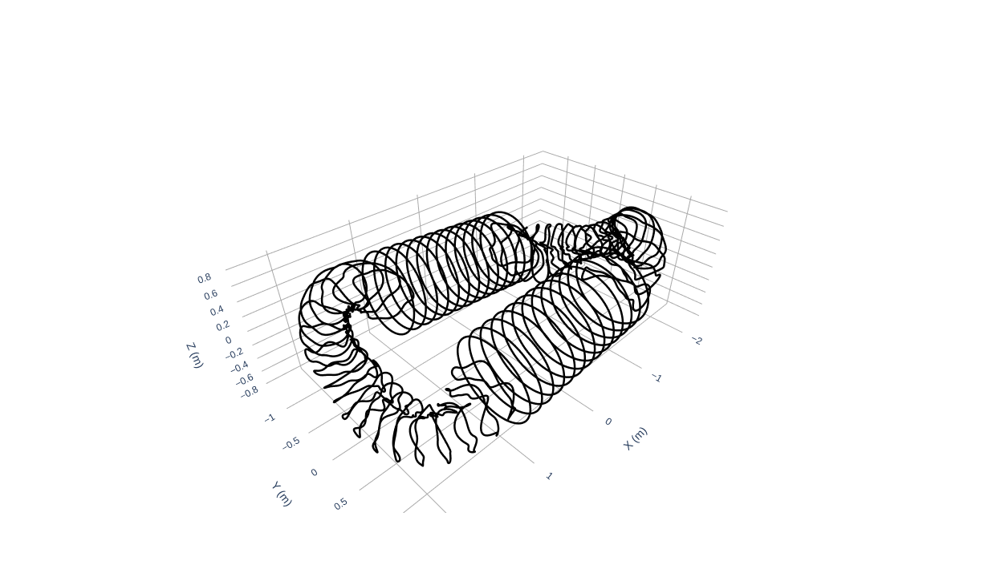

In [7]:
plot_coils(field)

In [8]:
x_solution = 1.0216246367096462

In [9]:
from desc.geometry import FourierRZCurve
grid_trace = LinearGrid(rho=np.array([0.]), theta=np.array([0.]), zeta=np.array([0.]))
#r0 = [x_solution + eq.compute("R", grid=grid_trace)["R"][0].item()]
r0 =  [1.0216246367096462 + eq.compute("R", grid=grid_trace)["R"][0].item()]
z0 = [0.]
#print(r0, z0)
nturns = 1
npoints_per_turn = 128
phi_full = np.linspace(0, 2 * np.pi * nturns, nturns * npoints_per_turn+1)
r, z = field_line_integrate(
   r0, z0, phis=phi_full, field=field, bounds_R=(0.65, 2.65), bounds_Z=(-1.0, 1.0)
)


data = np.array([r.flatten(), phi_full, z.flatten()]).T
curve = FourierRZCurve.from_values(coords=data, N=10)

#import pdb
#pdb.set_trace()

#curve.save("magnetic_axis_N10.h5")

theta = np.linspace(0., 2*np.pi, 256)
theta_2D, phi_2D = np.meshgrid(theta, phi_full, indexing="ij")

r = r.flatten()
z = z.flatten()
r = r[None, :] + 0.02*np.cos(theta_2D)
z = z[None, :] + 2*0.02*np.sin(theta_2D)
print(r.shape, phi_2D.shape, z.shape)
coords = np.vstack([r.flatten(), phi_2D.flatten(), z.flatten()]).T

M0 = 6
N0 = 14
surf0 = FourierRZToroidalSurface.from_values(coords=coords, theta=theta_2D.flatten(), M=M0, N=N0, NFP=2, sym=True, rcond=1e-7)


(256, 129) (256, 129) (256, 129)


/pscratch/sd/r/rgaur/DESC/desc/geometry/surface.py:203: UserWarning:

Left handed coordinates detected, switching sign of theta. To avoid this warning in the future, switch the sign of all modes with m<0. You may also need to switch the sign of iota or current profiles.



## Separating the shaping and non-shaping coils 

In [10]:
#field[1]
list1 = []
for i in range(10):
    list1.append(field[1][i]) 
coilset1 = CoilSet(list1, NFP=eq.NFP, sym=True, check_intersection=True)

list2 = []
list21 = []

shaping_coil = field[2][0]
#shaping_coil.change_resolution(N=1)
shaping_coil = shaping_coil.to_FourierXYZ(N=2)
#shaping_coil.to_FourierPlanar(basis="xyz")
#shaping_coil = shaping_coil.to_FourierXYZ(N=1)
shaping_coil1 = shaping_coil.copy()
#shaping_coil1 = shaping_coil1.to_FourierXY(basis="xyz")
#shaping_coil1.center = field[2][0].center
#shaping_coil1.normal = field[2][0].normal
#shaping_coil1.change_resolution(N=2)

# shaping_coil2 = field[2][2].copy()
# shaping_coil2.change_resolution(N=0)
# shaping_coil2 = shaping_coil2.to_FourierXY(basis="xyz")
# shaping_coil2.center = field[2][2].center
# shaping_coil2.normal = field[2][2].normal
# shaping_coil2.change_resolution(N=2)

list21.append(shaping_coil1)
#list21.append(shaping_coil2)
coilset21 = CoilSet(list21, NFP=eq.NFP, sym=True, check_intersection=True)


list2.append(shaping_coil) 
coilset2 = CoilSet(list2, NFP=eq.NFP, sym=True, check_intersection=True)

list3 = []
for i in np.arange(2, 12, 2):
    list3.append(field[2][i]) 
coilset3 = CoilSet(list3, NFP=eq.NFP, sym=True, check_intersection=True)

list4 = []
list4.append(field[2][12])
coilset4 = CoilSet(list4, sym=True, check_intersection=True)

#list5 = []
#list4.append(field[2][12]) 
#coilset5 = CoilSet.from_symmetry(list5, NFP=True, check_intersection=True)


#coilset1 = CoilSet.from_symmetry([field[0][:10], field[1][:10]], NFP=eq.NFP, sym=True, check_intersection=True)
#for coil in field[1]:
#    print(coil)

#field1 = MixedCoilSet([coilset1, coilset2, coilset3, coilset4]) 

field1 = MixedCoilSet([coilset1, coilset2, coilset3, coilset4]) 
field2 = MixedCoilSet([coilset1.copy(), coilset21, coilset3.copy(), coilset4.copy()]) 

fig = plot_coils(field1)
fig.show()
plt.figure()
fig = plot_coils(field2)
fig.show()

#field[1][2]

<Figure size 432x288 with 0 Axes>

In [11]:
#dir(shaping_coil1)
shaping_coil.X_n

Array([5.55111512e-17, 1.94289029e-16, 1.00000000e+00, 4.58944152e-02,
       2.91433544e-16], dtype=float64)

In [12]:
#plot_boundary(surf0)
fig = plot_coils(field1)
fig = plot_3d(surf0, name="R", fig=fig)
fig.show()

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



Building objective: Surface Quadratic Flux
Precomputing transforms
Timer: Precomputing transforms = 738 ms
Building objective: toroidal-flux
Precomputing transforms
Timer: Precomputing transforms = 336 ms
ObjectiveFunction deriv_mode : blocked
Surface Quadratic Flux jac_chunk_size: None
toroidal-flux jac_chunk_size: None
Timer: Objective build = 2.22 sec
Number of parameters: 1073
Number of objectives: 5266
Timer: Initializing the optimization = 2.25 sec

Starting optimization
Using method: lsq-exact
Solver options:
------------------------------------------------------------
Maximum Function Evaluations       : 501
Maximum Allowed Total Δx Norm      : inf
Scaled Termination                 : True
Trust Region Method                : qr
Initial Trust Radius               : 2.219e+00
Maximum Trust Radius               : inf
Minimum Trust Radius               : 2.220e-16
Trust Radius Increase Ratio        : 2.000e+00
Trust Radius Decrease Ratio        : 2.500e-01
Trust Radius Increase Th

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



<Figure size 432x288 with 0 Axes>

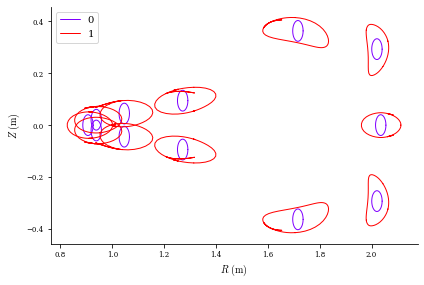

In [13]:
surf0.change_resolution(M=14, N=18)

surf0.rho = 1.0
surf0.iota = -0.512
surf0.G = 0.1

qflux = SurfaceQuadraticFlux(
    surf0,
    field1,
    eval_grid=LinearGrid(M=32, N=40, NFP=surf0.NFP),
    field_fixed=True,  # field is not being optimized
    bs_chunk_size=10,
    weight=1e-1
)

target_psi = -0.050
tflux = ToroidalFlux(
    surf0,
    field1,
    target=target_psi,  # the same toroidal flux as used in the free bdry eq
    eq_fixed=False,  # we will allow the thing passed in (QFM surface in this case) to vary
    field_fixed=True,  # field is not being optimized, so we fix it
    weight=1e3
)

#target_volume = 0.2
#volm = Volume(surface0, target=target_volume, weight=5e1)

obj = ObjectiveFunction((qflux, tflux))
#obj = ObjectiveFunction((qflux,))
#obj = ObjectiveFunction((qflux, volm))

#opt = Optimizer("lsq-auglag")
opt = Optimizer("lsq-exact")
#opt = Optimizer("proximal-lsq-exact")

constraints=(tflux,)

(qfm_surf1,), _ = opt.optimize(
    surf0,
    objective=obj,
    #constraints=constraints,
    ftol=5e-4,
    maxiter=100,
    verbose=3,
    copy=True,
)

#print(qfm_surf1.iota, qfm_surf1.G)

fig = plot_coils(field1)
fig = plot_3d(qfm_surf1, name="R", fig=fig)
#fig.write_html("test0.html")

plt.figure()
plot_boundaries([surf0, qfm_surf1], phi=12)
plt.savefig("test.png", dpi=400)

(<Figure size 2880x2880 with 1 Axes>,
 <Axes: xlabel='$R ~(\\mathrm{m})$', ylabel='$Z ~(\\mathrm{m})$'>)

<Figure size 432x288 with 0 Axes>

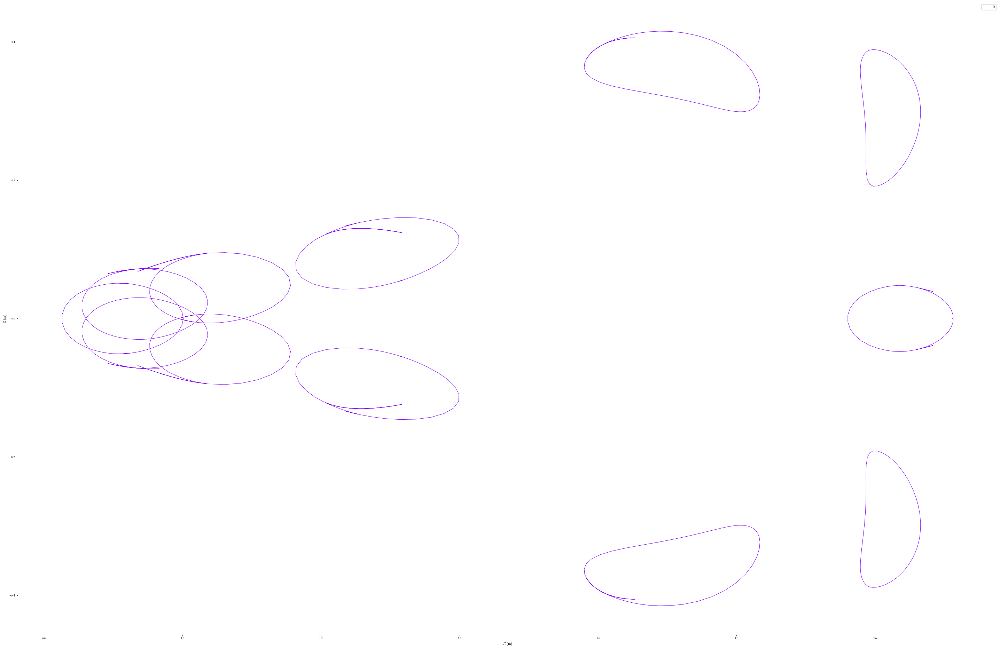

In [14]:
qfm_surf1.save("target_QFM_surface_hres_30-08-26.h5")
plt.figure()
plot_boundaries([qfm_surf1], phi=12, figsize=(40, 40))

## Re-sampling and re=fitting to the initial QFM surface for smoothness

In [15]:
phi_full = np.linspace(0, 2*np.pi, 96)
axis_data = curve.compute(["R", "Z"], grid=LinearGrid(zeta=phi_full))
r_axis = axis_data["R"]
z_axis = axis_data["Z"]

qfm_surf_grid = LinearGrid(rho=1., M=64, zeta=phi_full)
qfm_surf_data = qfm_surf1.compute(["R", "Z"], grid=qfm_surf_grid)
r = qfm_surf_data["R"]
z = qfm_surf_data["Z"]
#theta_arctan = np.arctan2(z-z_axis, r-r_axis)

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



In [16]:
# surf0.change_resolution(M=12, N=16)

# surf0.rho = 1.0
# surf0.iota = -0.512
# surf0.G = 0.1

# qflux = SurfaceQuadraticFlux(
#     surf0,
#     field2,
#     eval_grid=LinearGrid(M=24, N=32, NFP=surf0.NFP),
#     field_fixed=True,  # field is not being optimized
#     bs_chunk_size=10,
#     weight=1e-1
# )

# target_psi = -0.050
# tflux = ToroidalFlux(
#     surf0,
#     field2,
#     target=target_psi,  # the same toroidal flux as used in the free bdry eq
#     eq_fixed=False,  # we will allow the thing passed in (QFM surface in this case) to vary
#     field_fixed=True,  # field is not being optimized, so we fix it
#     weight=1e3
# )

# #target_volume = 0.2
# #volm = Volume(surface0, target=target_volume, weight=5e1)

# obj = ObjectiveFunction((qflux, tflux))
# #obj = ObjectiveFunction((qflux,))
# #obj = ObjectiveFunction((qflux, volm))

# #opt = Optimizer("lsq-auglag")
# opt = Optimizer("lsq-exact")
# #opt = Optimizer("proximal-lsq-exact")

# constraints=(tflux,)

# (qfm_surf2,), _ = opt.optimize(
#     surf0,
#     objective=obj,
#     #constraints=constraints,
#     ftol=5e-4,
#     maxiter=100,
#     verbose=3,
#     copy=True,
# )

# #print(qfm_surf1.iota, qfm_surf1.G)

# fig = plot_coils(field2)
# fig = plot_3d(qfm_surf2, name="R", fig=fig)
# #fig.write_html("test0.html")

# plt.figure()
# plot_boundaries([qfm_surf1, qfm_surf2], phi=12)
# plt.savefig("test.png", dpi=400)

In [17]:
# plt.figure()
# plot_boundaries([qfm_surf1, qfm_surf2], phi=24, figsize=(40, 40))
# plt.savefig("test.png", dpi=400)

In [18]:
Elongation_grid = LinearGrid(M = 2*int(surf0.M), zeta=np.array([0.]), rho=np.array([1.0]), NFP=eq.NFP, sym=False, axis=False)
print(qfm_surf1.compute("a_major/a_minor", grid=Elongation_grid)["a_major/a_minor"])

print(qfm_surf1.compute("V")["V"])

[3.51243951 3.51243951 3.51243951 3.51243951 3.51243951 3.51243951
 3.51243951 3.51243951 3.51243951 3.51243951 3.51243951 3.51243951
 3.51243951 3.51243951 3.51243951 3.51243951 3.51243951 3.51243951
 3.51243951 3.51243951 3.51243951 3.51243951 3.51243951 3.51243951
 3.51243951 3.51243951 3.51243951 3.51243951 3.51243951 3.51243951
 3.51243951 3.51243951 3.51243951 3.51243951 3.51243951 3.51243951
 3.51243951 3.51243951 3.51243951 3.51243951 3.51243951 3.51243951
 3.51243951 3.51243951 3.51243951 3.51243951 3.51243951 3.51243951
 3.51243951 3.51243951 3.51243951 3.51243951 3.51243951 3.51243951
 3.51243951 3.51243951 3.51243951]
0.13869165566739894


In [19]:
target_psi = -0.050
Elongation_grid = LinearGrid(M = 2*int(surf0.M), zeta=np.array([np.pi/2]), rho=np.array([1.0]), NFP=eq.NFP, sym=False, axis=False)
coil_grid = LinearGrid(N=20)
#coilset2[2] = coilset2[2].change_resolution(N=1)
#coilset2[3] = coilset2[3].change_resolution(N=1)

#surfacet_grid = LinearGrid(rho=1.0, theta = np.linspace(0, 2*np.pi, 20), zeta=np.array([0.]), sym=False, NFP=1) 
surfacet_grid = LinearGrid(rho=1.0, theta = np.linspace(0, 2*np.pi, 20), zeta=np.linspace(-np.pi/4 + 0.2, np.pi/4 - 0.2, 5),  sym=False, NFP=1) 

field2[1][0].current = -500000

def Zc(X):
    return -0.096502*X

# grid for SLAMElongation: a toroidal wedge that isolates ONE X0=0.4 cross-section
theta_s = np.linspace(0, 2*np.pi, 128, endpoint=False)
zeta_s  = np.linspace(np.pi/8, np.pi/2, 128, endpoint=True)   # as in your prototype
SLAM_grid = LinearGrid(theta=theta_s, zeta=zeta_s, NFP=1, sym=False)



bounds_length = (0.0, [2*np.pi,      # coil_1  fixed
                       2*np.pi*.6,   # coil_3  2 shaping coils, un-fixed later
                       2*np.pi,      # coil_4  fixed
                       2*np.pi])     # coil_6  4 limiters, fixed


#SLAMElongation(surf0, X0=[0.0, 0.1, 0.2, 0.4, .55], bounds=(1.0, 1.001), grid=SLAM_grid, weight=80.0),

X0_array = np.array([0.01, 0.15, 0.3, 0.45, 0.6, 0.75, 0.9])
Z0_array = Zc(X0_array)

target_volume = 0.135
obj = ObjectiveFunction((SurfaceQuadraticFlux(surf0, field2, eval_grid=LinearGrid(M=20, N=24, NFP=surf0.NFP, sym=True), field_fixed=False, bs_chunk_size=64,weight=1.0), 
                         ToroidalFlux(surf0, field2, target=target_psi, eq_fixed=False, field_fixed=False, weight=20),
                         SLAMElongation(surf0, X0=[0.01, 0.15, 0.3, 0.45, 0.6, 0.75, 0.9], slope=-0.096502, bounds=(1.0, 1.0001), grid=SLAM_grid, weight=0.95),
                         #SLAMCenter(surf0, X0=X0_array.tolist(), Y0=[0.888, 0.888, 0.888, 0.888, 0.888], Z0=Z0_array.tolist(),grid=SLAM_grid, weight=0.1),
                         SLAMStraightSectionCenter(surf0, X0=X0_array.tolist(), Z0=Z0_array.tolist(), grid=SLAM_grid, weight=4.0),
                         SurfaceMatch(surf0, qfm_surf1, surfacet_fixed=True, surfacet_grid=surfacet_grid, weight=0.7),
                         CoilSetMinDistance(field2,bounds=(0.023,100),grid=LinearGrid(N=100), weight=10, deriv_mode="fwd"),
                         CoilLength(field2, bounds=bounds_length, normalize_target=True, weight=5, grid=coil_grid, deriv_mode="fwd"),
                         Elongation(eq=surf0, bounds=(1.0, 1.03), grid=Elongation_grid, weight=0.8),
                        ))


constraints = (FixParameters(field2,[{"X_n":True,"Y_n": True,"Z_n":True, "current":True},\
                                       #{"r_n":False, "center":False, "normal":False, "current":False},\
                                       #{"X_n":[1], "Y_n":[0], "center":True, "normal":True, "current":True},\
                                       #{"X_n":False, "Y_n":False, "center":True, "normal":True, "current":False},\
                                       {"current":True},\
                                       #{},\
                                       {"r_n":True, "center":True, "normal":True, "current":True},\
                                       {"r_n":True, "center":True, "normal":True, "current":True}]),)
                                       #SLAMElongation(surf0, X0=[0.01, 0.15, 0.3, 0.45, 0.6, 0.75, 0.85], slope=-0.096502, bounds=(1.0, 1.0001), grid=SLAM_grid, weight=0.9),)

#constraints = (FixParameters(coilset2,[{}, {}, {"r_n":False, "center":False, "normal":False},\
#                     {"r_n":False, "center":False, "normal":False}, {}, {}]),)
#constraints = ((FixParameters(field,[{}, {}, {}, {}, {}, {}]),))

opt = Optimizer("lsq-auglag")
#opt = Optimizer("lsq-exact")
#opt = Optimizer("proximal-lsq-exact")

[qfm_surf,field2_opt], _ = opt.optimize(
    [surf0, field2],
    objective=obj,
    constraints=constraints,
    ftol=1e-10,
    xtol=1e-10,
    maxiter=150,
    verbose=3,
    copy=True,
    options={"tr_decrease_ratio":0.75}
)


Building objective: Surface Quadratic Flux
Precomputing transforms
Timer: Precomputing transforms = 371 ms
Building objective: toroidal-flux
Precomputing transforms
Timer: Precomputing transforms = 40.5 ms
Building objective: SLAM elongation
Precomputing transforms


/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



Timer: Precomputing transforms = 330 ms
Building objective: SLAM straight-section center
Precomputing transforms


/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



Timer: Precomputing transforms = 54.2 ms
Building objective: Surface Match
Precomputing transforms


...

Timer: Precomputing transforms = 355 ms
Building objective: coil-coil minimum distance
Building objective: coil length
Precomputing transforms
Timer: Precomputing transforms = 183 ms
Building objective: elongation
Precomputing transforms
Timer: Precomputing transforms = 50.4 ms
ObjectiveFunction deriv_mode : blocked
Surface Quadratic Flux jac_chunk_size: None
toroidal-flux jac_chunk_size: None
SLAM elongation jac_chunk_size: None
SLAM straight-section center jac_chunk_size: None
Surface Match jac_chunk_size: None
coil-coil minimum distance jac_chunk_size: None
coil length jac_chunk_size: None
elongation jac_chunk_size: None
Timer: Objective build = 3.60 sec
Building objective: fixed parameters
Building objective: fixed shift
Building objective: fixed rotation
ObjectiveFunction deriv_mode : blocked
fixed parameters jac_chunk_size: None
fixed shift jac_chunk_size: None
fixed rotation jac_chunk_size: None
Timer: Objective build = 524 ms
Timer: LinearConstraintProjection build = 3.94 sec
N

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: FutureWarning:

constants is deprecated and will be removed in a future release. Users should not include constants in the arguments of their objective compute methods. Instead declare all the constants in the build method and use as self._constants.

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: FutureWarning:

constants is deprecated and will be removed in a future release. Users should not include constants in the arguments of their objective compute methods. Instead declare all the constants in the build method and use as self._constants.



Solver options:
------------------------------------------------------------
Maximum Function Evaluations       : 751
Maximum Allowed Total Δx Norm      : inf
Scaled Termination                 : True
Trust Region Method                : qr
Initial Trust Radius               : 4.141e-01
Maximum Trust Radius               : inf
Minimum Trust Radius               : 2.220e-16
Trust Radius Increase Ratio        : 4.000e+00
Trust Radius Decrease Ratio        : 7.500e-01
Trust Radius Increase Threshold    : 7.500e-01
Trust Radius Decrease Threshold    : 5.000e-01
Alpha Omega                        : 1.000e+00
Beta Omega                         : 1.000e+00
Alpha Eta                          : 1.000e-01
Beta Eta                           : 9.000e-01
Omega                              : 1.000e-02
Eta                                : 0.000e+00
Tau                                : 9.000e-01
------------------------------------------------------------ 

   Iteration     Total nfev        Cost     

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: FutureWarning:

constants is deprecated and will be removed in a future release. Users should not include constants in the arguments of their objective compute methods. Instead declare all the constants in the build method and use as self._constants.



                                                                 Start  -->   End
Total (sum of squares):                                      2.690e+01  -->   5.078e-02, 
Maximum absolute QFM surface normal field error:             5.915e-02  -->   9.750e-03 (T m^2)
Minimum absolute QFM surface normal field error:             3.537e-06  -->   2.032e-06 (T m^2)
Average absolute QFM surface normal field error:             1.293e-02  -->   1.940e-03 (T m^2)
Maximum absolute QFM surface normal field error:             1.201e-01  -->   1.979e-02 (normalized)
Minimum absolute QFM surface normal field error:             7.179e-06  -->   4.126e-06 (normalized)
Average absolute QFM surface normal field error:             2.624e-02  -->   3.939e-03 (normalized)
Maximum Toroidal Flux:                                      -1.110e-02  -->  -4.910e-02 (Wb)
Minimum Toroidal Flux:                                      -1.110e-02  -->  -4.910e-02 (Wb)
Average Toroidal Flux:                             

In [20]:
fig = plot_coils(field2_opt)
fig = plot_3d(qfm_surf, name="R", fig=fig)
fig.show()

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



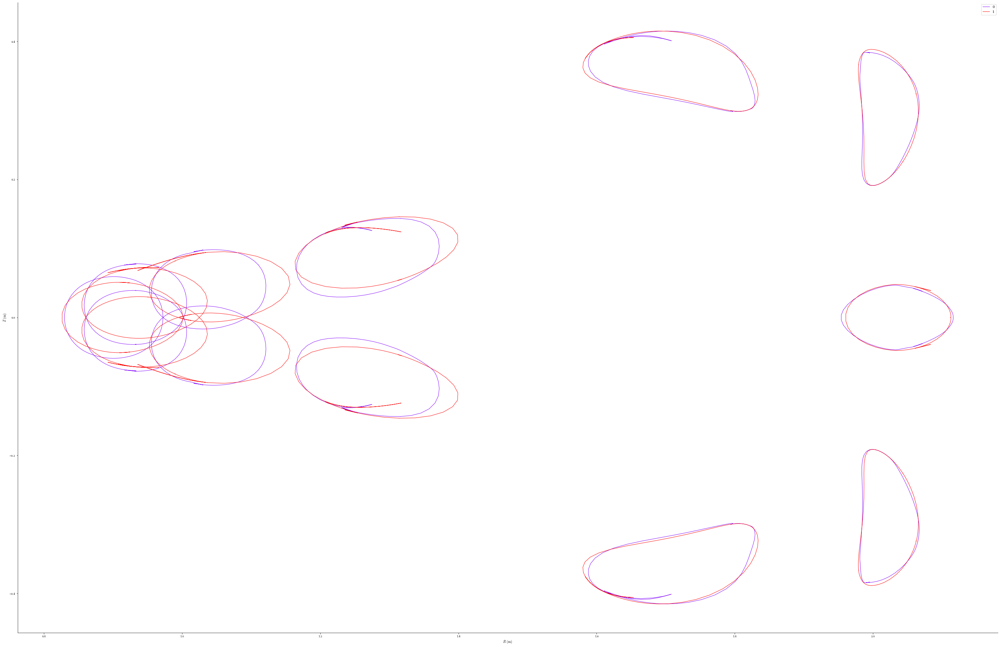

In [21]:
fig, ax = plot_boundaries([qfm_surf, qfm_surf1], phi=12, figsize=(40, 40))
#fig, ax = plot_boundaries([qfm_surf], phi=12, figsize=(40, 40))
fig.show()

In [22]:
from scipy.interpolate import InterpolatedUnivariateSpline

def find_magnetic_axis_and_B(
    field,
    eq=None,
    R0_guess=None,
    dR_scan=0.1,
    n_scan=100,
    npoints_per_turn=513,
    nturns=1,
    bounds_R=(0.5, 5.0),
    bounds_Z=(-1.2, 1.2),
    source_grid=50,
):
    """Find the magnetic axis of a coilset by field line tracing, and
    evaluate |B| along it.

    Ported from the axis-finding logic in `boozer_spline.py`.

    Parameters
    ----------
    field : MagneticField (e.g. CoilSet)
        The coilset/field to trace field lines through.
    eq : Equilibrium, optional
        Used only to get an initial guess for R0 (the R at rho=0) if
        `R0_guess` is not given directly. One of `eq` or `R0_guess` is
        required.
    R0_guess : float, optional
        Initial guess for the magnetic axis major radius.
    dR_scan : float
        Half-width of the R window (about R0_guess) to scan when
        bracketing the axis location.
    n_scan : int
        Number of points in the coarse R scan.
    npoints_per_turn : int
        Number of phi points used to resolve the refined axis curve (and
        hence |B| on axis).
    nturns : int
        Number of toroidal turns to trace for the refined axis.
    bounds_R, bounds_Z : tuple
        R, Z bounds passed to `field_line_integrate` so the integrator
        doesn't wander into unphysical regions.
    source_grid : int
        Source grid resolution used in `field.compute_magnetic_field`.

    Returns
    -------
    dict with keys
        R_shift : float, axis R offset relative to R0_guess
        R0_guess : float, the R0 guess that was used
        phi_axis : ndarray, toroidal angle grid for the axis
        r_axis, z_axis : ndarray, axis (R, Z) on phi_axis
        B_axis : ndarray, |B| on axis, same shape as phi_axis
        B_axis_avg : float, mean |B| on axis
    """
    if R0_guess is None:
        if eq is None:
            raise ValueError("Must supply either `eq` or `R0_guess`.")
        grid0 = LinearGrid(rho=np.array([0.0]))
        R0_guess = eq.compute("R", grid=grid0)["R"][0]

    # ---- Step 1: coarse scan to bracket the axis on the midplane ----
    phi_scan = np.linspace(0, 2 * np.pi, 2)  # phi=0 and phi=2*pi (one turn)
    x = np.linspace(R0_guess - dR_scan, R0_guess + dR_scan, n_scan)
    r0 = [x]
    z0 = [np.zeros_like(x)]
    r, z = field_line_integrate(
        r0, z0, phis=phi_scan, field=field, bounds_R=bounds_R, bounds_Z=bounds_Z
    )
    spline = InterpolatedUnivariateSpline(x, z[0] - z[1], k=3)
    roots = spline.roots()
    if len(roots) == 0:
        raise RuntimeError(
            "No axis crossing found in the scan window; try increasing "
            "dR_scan or adjusting R0_guess."
        )
    root = roots[np.argmin(np.abs(roots - R0_guess))]
    R_shift = root - R0_guess
    print(f"R_shift: {R_shift}")

    # ---- Step 2: refine with a well-resolved field line trace ----
    phi_axis = np.linspace(
        0, 2 * np.pi * nturns, nturns * npoints_per_turn, endpoint=False
    )
    r0 = [R_shift + R0_guess]
    z0 = [0.0]
    r_axis, z_axis = field_line_integrate(
        r0, z0, phis=phi_axis, field=field, bounds_R=bounds_R, bounds_Z=bounds_Z
    )
    r_axis = r_axis.flatten()
    z_axis = z_axis.flatten()

    # ---- Step 3: evaluate |B| on the axis ----
    coords = np.vstack(
        (r_axis * np.cos(phi_axis), r_axis * np.sin(phi_axis), z_axis)
    ).T
    Bvec = field.compute_magnetic_field(
        coords=coords, basis="xyz", source_grid=source_grid
    )
    B_axis = np.linalg.norm(Bvec, axis=-1)

    return {
        "R_shift": R_shift,
        "R0_guess": R0_guess,
        "phi_axis": phi_axis,
        "r_axis": r_axis,
        "z_axis": z_axis,
        "B_axis": B_axis,
        "B_axis_avg": np.mean(B_axis),
    }


R_shift: -0.04477444449844903
R_shift: -0.048834818939352154


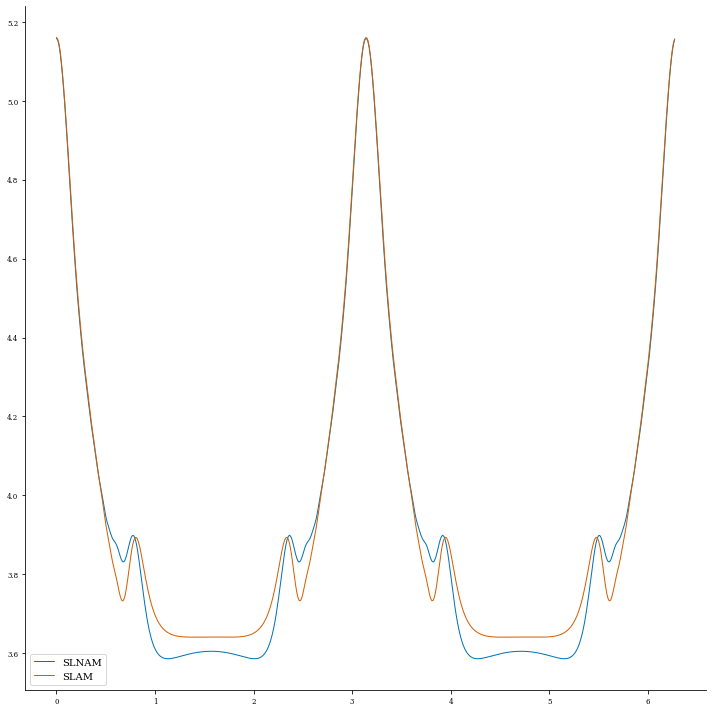

In [23]:
from matplotlib import pyplot as plt
plt.figure(figsize=(10, 10))
data0 = find_magnetic_axis_and_B(field1, eq=eq, R0_guess=2.08)
data1 = find_magnetic_axis_and_B(field2_opt, eq=eq, R0_guess=2.08)
plt.plot(data0["phi_axis"], data0["B_axis"], label="SLNAM") 
plt.plot(data1["phi_axis"], data1["B_axis"], label="SLAM")
plt.legend()
plt.tight_layout()


#plt.plot(data1["phi_axis"], data1["B_axis"])

In [76]:
# field2_opt.save("SLAM-field-09-09-26_2.h5")
# field2.save("SLNAM-field-09-09-26_2.h5")
# qfm_surf.save("SLAM_QFM_surface_09-09-26_2.h5")